# GW analysis of monolayer and bilayer hBN

Yambo (Lumen fork, `bug-fixes` build) G0W0 calculations for the first benchmark of the project
(`docs/04_benchmark_systems.md`): explicit bilayer hBN vs monolayer + second layer as an effective substrate.
The GW parameters are converged on the monolayer (`ML_bot`) and used unchanged for all the systems.

Choices (user, 2026-11-11):
- k grids 18x18x1, 30x30x1, 42x42x1 (they contain K and M), nscf with 250 bands: upper bound of all the band
  parameters of the GW runs (`DFT_Analysis.ipynb`, section "NSCF on regular grids").
- Coulomb interaction: slab cutoff `CUTGeo='slab z'` and RIM on v in every run, RandQpts = 5000000, RandGvec = 100
  (values of the MoS2 study, not re-converged).
- HF runs with RIM only; all the GW (PPA) runs with RIM_W, RandGvecW = 10.

How to run: execute the cells in order; every dataset uses `skip=True` (existing results are not recomputed) and at
most 2 slurm jobs at a time (project rule: at most 2 nodes).

In [1]:
# useful to autoreload the module without restarting the kernel
%load_ext autoreload
%autoreload 2

In [2]:
from mppi import InputFiles as I, Calculators as C, Datasets as D, Parsers as P, Utilities as U
from mppi.Calculators import Tools
from mppi.Datasets import PostProcessing as PP
from mppi.Utilities import Constants as Const
import matplotlib.pyplot as plt
import numpy as np
import os

In [3]:
# Calculator factory for ismhpc (32 cores per node, 32 MPI x 1 OMP for yambo)
module = '/home/dalessandro/module_script/yambo_module'

def yambo_code(nodes=1, partition='all12h', time='11:59:00', executable='yambo'):
    rr = C.RunRules(scheduler='slurm', partition=partition, memory='125000', time=time, nodes=nodes,
                    ntasks_per_node=32, cpus_per_task=1, omp_num_threads=1, pre_processing=module)
    return C.YamboCalculator(rr, executable=executable, activate_BeeOND=True)

## SAVE databases
One yambo folder per nscf: `MB_analysis/<nscf prefix>/SAVE`, built with `Tools.init_yambo_dir` (p2y + yambo setup
`r_setup`). p2y and the setup are serial and light: they run directly on the login node with 1 MPI and 1 OMP (user,
2026-11-11). Folders whose SAVE and `r_setup` already exist are skipped. The Lumen p2y ends with MPI_ABORT after
writing the databases: the SAVE is complete anyway (checked below). (Launching the OpenMPI p2y with `srun` hangs at
start-up on ismhpc.)

In [4]:
dft_dir = 'DFT_analysis'
mb_dir = 'MB_analysis'
saves = [('ML_bot', 18, 250), ('ML_bot', 30, 250), ('ML_bot', 42, 250),   # (system, k, bands) of the nscf runs
         ('AA1', 18, 400), ('AB', 18, 400)]

def nscf_name(system, k, nbnds):
    return 'kpoints_%s-nbnds_%s-%s' % (k, nbnds, system)

def yambo_dir(system, k, nbnds):
    return os.path.join(mb_dir, nscf_name(system, k, nbnds))

def build_save(system, k, nbnds):
    Tools.init_yambo_dir(yambo_dir=yambo_dir(system, k, nbnds),
                         input_dir=os.path.join(dft_dir, nscf_name(system, k, nbnds) + '.save'),
                         p2y_command='OMP_NUM_THREADS=1 mpirun -np 1 p2y',
                         yambo_command='OMP_NUM_THREADS=1 mpirun -np 1 yambo')

for s, k, nb in saves:
    build_save(s, k, nb)

SAVE folder MB_analysis/kpoints_18-nbnds_250-ML_bot/SAVE already present. No operations performed.
SAVE folder MB_analysis/kpoints_30-nbnds_250-ML_bot/SAVE already present. No operations performed.
SAVE folder MB_analysis/kpoints_42-nbnds_250-ML_bot/SAVE already present. No operations performed.
SAVE folder MB_analysis/kpoints_18-nbnds_400-AA1/SAVE already present. No operations performed.
SAVE folder MB_analysis/kpoints_18-nbnds_400-AB/SAVE already present. No operations performed.


In [5]:
def check_save(system, k, nbnds):
    folder = yambo_dir(system, k, nbnds)
    save = os.path.join(folder, 'SAVE')
    nwf = len([f for f in os.listdir(save) if f.startswith('ns.wf')])
    db = P.YamboDftParser(os.path.join(save, 'ns.db1'))
    with open(os.path.join(folder, 'r_setup')) as f: setup = f.read()
    print('%-30s %4d k points (IBZ) | %d bands | %d ns.wf files | r_setup %s'
          % (folder, len(db.get_kpoints()), db.nbands, nwf, 'ok' if 'Game Over' in setup else 'INCOMPLETE'))

for s, k, nb in saves:
    check_save(s, k, nb)

Parse file : MB_analysis/kpoints_18-nbnds_250-ML_bot/SAVE/ns.db1
MB_analysis/kpoints_18-nbnds_250-ML_bot   37 k points (IBZ) | 250 bands | 38 ns.wf files | r_setup ok
Parse file : MB_analysis/kpoints_30-nbnds_250-ML_bot/SAVE/ns.db1
MB_analysis/kpoints_30-nbnds_250-ML_bot   91 k points (IBZ) | 250 bands | 92 ns.wf files | r_setup ok
Parse file : MB_analysis/kpoints_42-nbnds_250-ML_bot/SAVE/ns.db1
MB_analysis/kpoints_42-nbnds_250-ML_bot  169 k points (IBZ) | 250 bands | 170 ns.wf files | r_setup ok
Parse file : MB_analysis/kpoints_18-nbnds_400-AA1/SAVE/ns.db1
MB_analysis/kpoints_18-nbnds_400-AA1   37 k points (IBZ) | 400 bands | 38 ns.wf files | r_setup ok
Parse file : MB_analysis/kpoints_18-nbnds_400-AB/SAVE/ns.db1
MB_analysis/kpoints_18-nbnds_400-AB   37 k points (IBZ) | 400 bands | 38 ns.wf files | r_setup ok


## HF on the monolayer: cutoff of the exchange term
`ML_bot`, k = 18x18x1 (`kpoints_18-nbnds_250-ML_bot`). Coulomb interaction: `CUTGeo='slab z'` + RIM (RandQpts = 5e6,
RandGvec = 100 RL, values fixed by the user). Scan of the exchange cutoff EXXRLvcs = VXCRLvcs (the same value for the
exchange and for the xc potential, which are subtracted). HF corrections of the top valence and bottom conduction
bands (4, 5) at all the 37 k points of the IBZ (cheap at this level): the control quantities are the gaps at K
(k index 37) and at $\Gamma$ (k index 1), and the single states at K.

Shared databases: yambo writes the new databases in the FIRST folder of the `-J` list and reads them from all the
folders. The RIM and cutoff databases are therefore computed once by a dedicated run (`yambo -r`, name and job
`ndb_rim_cutoff`) and read by all the following runs (`jobname=[name, 'ndb_rim_cutoff']`).

Parallel structure of the HF runlevel of this yambo (`-V all`): `SX_ROLEs`/`SX_CPU`. The role `b` runs over the
bands up to the highest corrected one (5 here), so it cannot take many tasks: the 32 MPI are split over the q
points (37) and the QP states (74): `SX_CPU = 8.4.1`.

In [6]:
hf_system, hf_k, hf_nbnds = 'ML_bot', 18, 250
run_dir = yambo_dir(hf_system, hf_k, hf_nbnds)
Gamma_index, K_index = 1, 37
start_band, stop_band = 4, 5          # top valence, bottom conduction (8 valence electrons)
RandQpts = 5000000
RandGvec = 100                         # RL

yambo_cmd = 'OMP_NUM_THREADS=1 mpirun -np 1 yambo'   # only to generate the inputs (login node)

def build_rim_input(folder=run_dir):
    # RIM and slab cutoff only: databases shared by all the runs of the folder (ndb_rim_cutoff)
    inp = I.YamboInput(args='%s -r -V all' % yambo_cmd, folder=folder)
    inp.set_scalar_variables(CUTGeo='slab z')
    inp.set_array_variables(RandQpts=RandQpts)
    inp.set_array_variables(units='RL', RandGvec=RandGvec)
    return inp

def run_rim(folder=run_dir):
    code = yambo_code()
    code.run(input=build_rim_input(folder), run_dir=folder, name='ndb_rim_cutoff', jobname='ndb_rim_cutoff', skip=True)

def build_hf_input(exx, folder=run_dir):
    inp = I.YamboInput(args='%s -r -x -V all' % yambo_cmd, folder=folder)
    inp.set_scalar_variables(CUTGeo='slab z')
    inp.set_array_variables(RandQpts=RandQpts)
    inp.set_array_variables(units='RL', RandGvec=RandGvec)
    inp.set_array_variables(units='Ha', EXXRLvcs=exx, VXCRLvcs=exx)
    inp.set_bandRange(start_band, stop_band)
    inp.set_scalar_variables(SX_ROLEs='q.qp.b', SX_CPU='8.4.1')    # 32 MPI on one node: q x qp (b has only 5 elements)
    return inp

build_hf_input(30.)

{'args': 'OMP_NUM_THREADS=1 mpirun -np 1 yambo -r -x -V all',
 'folder': 'MB_analysis/kpoints_18-nbnds_250-ML_bot',
 'filename': 'yambo.in',
 'arguments': ['rim_cut', 'HF_and_locXC', 'infver'],
 'variables': {'StdoHash': [40, ''],
  'Nelectro': [8.0, ''],
  'NelCond': [0.0, ''],
  'ElecTemp': [0.0, 'eV'],
  'BoseTemp': [-1.0, 'eV'],
  'OccTresh': [1e-05, ''],
  'NLogCPUs': [0, ''],
  'DBsIOoff': 'none',
  'DBsFRAGpm': 'none',
  'MEM_tresh': [88865, 'Kb'],
  'FFTGvecs': [12311, 'RL'],
  'PAR_def_mode': 'balanced',
  'SX_CPU': '8.4.1',
  'SX_ROLEs': 'q.qp.b',
  'SX_Threads': [0, ''],
  'BZINDX_CPU': '',
  'BZINDX_ROLEs': '',
  'RandQpts': [5000000, ''],
  'RandGvec': [100, 'RL'],
  'Em1Anys': [[0.0, 0.0, 0.0], ''],
  'IDEm1Ref': [0, ''],
  'CUTGeo': 'slab z',
  'CUTBox': [[0.0, 0.0, 0.0], ''],
  'CUTRadius': [0.0, ''],
  'CUTwsGvec': [0.7, ''],
  'EpsEnv': [1.0, ''],
  'EXXRLvcs': [30.0, 'Ha'],
  'VXCRLvcs': [30.0, 'Ha'],
  'QPkrange': [[1, 37, 4, 5], ''],
  'QPerange': [[1, 37, 0.0, -1.

In [7]:
EXXRLvcs = [10., 20., 30., 40., 50., 60.]   # Ha

run_rim()                    # shared RIM + cutoff databases (skipped if already computed)
code = yambo_code()
study = D.Dataset(run_dir=run_dir, num_tasks=2)
study.set_postprocessing_function(PP.yambo_parse_data)
for exx in EXXRLvcs:
    name = 'hf-exxrlvcs_%s' % exx
    assert len(name) <= 100
    study.append_run(id={'exx': exx}, input=build_hf_input(exx), runner=code, run_dir=run_dir, name=name,
                     jobname=[name, 'ndb_rim_cutoff'], skip=True)
results = study.run()

Initialize a Yambo calculator with scheduler slurm


Skip the run of ndb_rim_cutoff



        There are no o-* files.
        Maybe you have performed a computation that does not create any output file or wait_end_run
        and/or the dry_run option are active.
        Otherwise a possible error has occured during the computation
        
Initialize a Yambo calculator with scheduler slurm
Initialize a Dataset with 2 parallel tasks


Run the selection [0, 1, 2, 3, 4, 5] with the parallel task_groups [[0, 1], [2, 3], [4, 5]] 

Run the task [0, 1] 


Skip the run of

Skip the run of

... (9 outputs left out)

Skip the run of

hf-exxrlvcs_60.0

hf-exxrlvcs_50.0

Task [4, 5] ended 
 


EXXRLvcs =   10 Ha | HF gap at K = 13.1701 eV | at Gamma = 12.9471 eV | E_hf(K): v = -3.2180, c = 9.9521 eV
EXXRLvcs =   20 Ha | HF gap at K = 13.3226 eV | at Gamma = 13.0658 eV | E_hf(K): v = -3.3743, c = 9.9483 eV
EXXRLvcs =   30 Ha | HF gap at K = 13.3362 eV | at Gamma = 13.0686 eV | E_hf(K): v = -3.3850, c = 9.9512 eV
EXXRLvcs =   40 Ha | HF gap at K = 13.3354 eV | at Gamma = 13.0551 eV | E_hf(K): v = -3.3859, c = 9.9495 eV
EXXRLvcs =   50 Ha | HF gap at K = 13.3167 eV | at Gamma = 13.0191 eV | E_hf(K): v = -3.3662, c = 9.9506 eV
EXXRLvcs =   60 Ha | HF gap at K = 13.3207 eV | at Gamma = 12.9397 eV | E_hf(K): v = -3.3717, c = 9.9490 eV


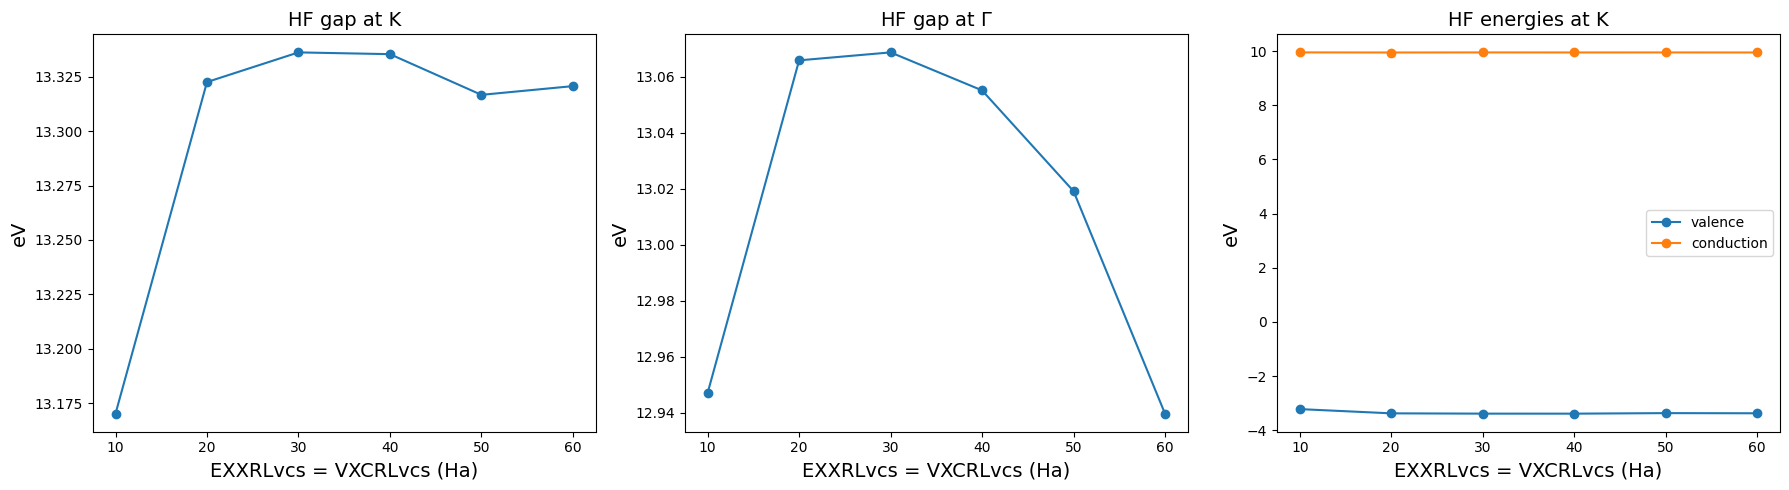

In [8]:
data = [study.fetch_results(id={'exx': exx})[0].data for exx in EXXRLvcs]
gap_K = [d.get_gap(k_full=K_index, band_full=start_band) for d in data]
gap_G = [d.get_gap(k_full=Gamma_index, band_full=start_band) for d in data]
v_K = [d.get_energy(K_index, start_band) for d in data]
c_K = [d.get_energy(K_index, stop_band) for d in data]
for exx, gk, gg, v, c in zip(EXXRLvcs, gap_K, gap_G, v_K, c_K):
    print('EXXRLvcs = %4.0f Ha | HF gap at K = %.4f eV | at Gamma = %.4f eV | E_hf(K): v = %.4f, c = %.4f eV'
          % (exx, gk, gg, v, c))

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))
ax[0].plot(EXXRLvcs, gap_K, 'o-'); ax[0].set_title('HF gap at K', size=14)
ax[1].plot(EXXRLvcs, gap_G, 'o-'); ax[1].set_title(r'HF gap at $\Gamma$', size=14)
ax[2].plot(EXXRLvcs, v_K, 'o-', label='valence'); ax[2].plot(EXXRLvcs, c_K, 'o-', label='conduction')
ax[2].set_title('HF energies at K', size=14); ax[2].legend()
for a in ax: a.set_xlabel('EXXRLvcs = VXCRLvcs (Ha)', size=14); a.set_ylabel('eV', size=14)
fig.tight_layout()

Result of the scan (k = 18): the exchange term Sx is converged from 30-40 Ha (single states within 3 meV), while the
xc term Vxc keeps changing above 40 Ha, most of all for the nearly-free-electron conduction state at $\Gamma$
(-3.855, -3.842, -3.822, -3.741 eV at 30, 40, 50, 60 Ha): with EXXRLvcs = VXCRLvcs the gap at $\Gamma$ drops by
0.13 eV between 30 and 60 Ha, the gap at K oscillates by 20 meV. Interpretation (to check): the NFE state extends into
the vacuum, where the PBE potential of the very low density is noisy and has large-G components; truncating Vxc in G
then gives a cutoff-dependent matrix element, with no cancellation against Sx.

Check (user, 2026-11-11): Vxc with all the G vectors of the density (24949 RL, the default of this yambo, about
80 Ha: Vxc is local and its matrix element is then exact), with EXXRLvcs = 40 Ha and with EXXRLvcs = full.

In [9]:
vxc_full = 24949    # RL: all the G vectors of the density (default of yambo -V all)

def build_hf_input_rl(exx, vxc, exx_units='Ha', folder=run_dir):
    inp = build_hf_input(30., folder=folder)
    inp.set_array_variables(units=exx_units, EXXRLvcs=exx)
    inp.set_array_variables(units='RL', VXCRLvcs=vxc)
    return inp

checks = {'exx_40Ha-vxc_full': (40., 'Ha'), 'exx_full-vxc_full': (vxc_full, 'RL')}
code = yambo_code()
study_vxc = D.Dataset(run_dir=run_dir, num_tasks=2)
study_vxc.set_postprocessing_function(PP.yambo_parse_data)
for label, (exx, units) in checks.items():
    name = 'hf-%s' % label
    study_vxc.append_run(id=label, input=build_hf_input_rl(exx, vxc_full, exx_units=units), runner=code,
                         run_dir=run_dir, name=name, jobname=[name, 'ndb_rim_cutoff'], skip=True)
results_vxc = study_vxc.run()

Initialize a Yambo calculator with scheduler slurm
Initialize a Dataset with 2 parallel tasks


Run the selection [0, 1] with the parallel task_groups [[0, 1]] 

Run the task [0, 1] 


Skip the run of

hf-exx_40Ha-vxc_full

Skip the run of

hf-exx_full-vxc_full

Task [0, 1] ended 
 


In [10]:
def hf_columns(name, k, b):
    # E0, Ehf, Vxc, Sx (eV) from the o-*.hf file of a run
    d = np.loadtxt(os.path.join(run_dir, name, 'o-%s.hf' % name), comments='#')
    row = d[(d[:, 0] == k) & (d[:, 1] == b)][0]
    return row[2:6]

runs = ['hf-exxrlvcs_%s' % e for e in EXXRLvcs] + ['hf-%s' % l for l in checks]
print('%-26s %9s %9s | %9s %9s %9s %9s | %9s %9s' % ('run', 'gap K', 'gap G', 'Vxc K v', 'Vxc G c', 'Sx K v', 'Sx G c',
                                                      'Ehf K v', 'Ehf K c'))
for name in runs:
    Kv, Kc = hf_columns(name, K_index, start_band), hf_columns(name, K_index, stop_band)
    Gv, Gc = hf_columns(name, Gamma_index, start_band), hf_columns(name, Gamma_index, stop_band)
    print('%-26s %9.4f %9.4f | %9.4f %9.4f %9.4f %9.4f | %9.4f %9.4f'
          % (name, Kc[1] - Kv[1], Gc[1] - Gv[1], Kv[2], Gc[2], Kv[3], Gc[3], Kv[1], Kc[1]))

run                            gap K     gap G |   Vxc K v   Vxc G c    Sx K v    Sx G c |   Ehf K v   Ehf K c
hf-exxrlvcs_10.0             13.1701   12.9471 |  -16.6122   -3.8532  -19.8302   -1.2982 |   -3.2180    9.9521
hf-exxrlvcs_20.0             13.3226   13.0658 |  -16.6119   -3.8550  -19.9862   -1.3021 |   -3.3743    9.9483
hf-exxrlvcs_30.0             13.3362   13.0686 |  -16.6191   -3.8553  -20.0041   -1.3022 |   -3.3850    9.9512
hf-exxrlvcs_40.0             13.3354   13.0551 |  -16.6207   -3.8424  -20.0066   -1.3022 |   -3.3859    9.9495
hf-exxrlvcs_50.0             13.3167   13.0191 |  -16.6407   -3.8224  -20.0068   -1.3022 |   -3.3662    9.9506
hf-exxrlvcs_60.0             13.3207   12.9397 |  -16.6351   -3.7410  -20.0068   -1.3022 |   -3.3717    9.9490
hf-exx_40Ha-vxc_full         13.3210   12.8630 |  -16.6348   -3.6631  -20.0066   -1.3022 |   -3.3718    9.9492
hf-exx_full-vxc_full         13.3212   12.8632 |  -16.6348   -3.6631  -20.0068   -1.3022 |   -3.3721    9.9492


Result of the check: with Vxc on all the G vectors of the density the results no longer depend on the exchange
cutoff (EXXRLvcs = 40 Ha and full differ by 0.3 meV): HF gap at K = 13.321 eV, at $\Gamma$ = 12.863 eV (k = 18).
The apparent plateau at 30-40 Ha of the EXXRLvcs = VXCRLvcs scan was an artefact of the truncated Vxc (+15 meV at K,
+0.2 eV at $\Gamma$).

Why: Vxc is a local potential; computed with all the G vectors of the density its matrix element is exactly the one
of the KS Hamiltonian that produced E0, so it is not a convergence parameter. Truncating it in G makes the result
cutoff dependent, most of all for the nearly-free-electron states that extend into the vacuum (conduction state at
$\Gamma$), where the PBE potential of the very low density has large-G components; the hoped-for cancellation of the
truncation errors of Sx and Vxc (EXXRLvcs = VXCRLvcs, MoS2 protocol) does not happen for these states.

**Choice (user, 2026-11-11): EXXRLvcs = VXCRLvcs = 24949 RL, all the G vectors of the density (the default of this
yambo).** Nothing to converge, and the cost is small: 17 s at k = 18 (6 s at EXXRLvcs = 40 Ha); the HF database is
computed once per k grid and then shared by the GW runs.

## HF on the monolayer: k grid
`ML_bot` on the 18, 30, 42 grids with the chosen parameters (RIM 5e6/100, EXXRLvcs = VXCRLvcs = all the G vectors).
In each folder the RIM/cutoff databases are first computed by the dedicated run `ndb_rim_cutoff` (they depend on the
q grid), then the HF run reads them. The index of K in the IBZ list of each grid is found from the SAVE.

In [11]:
def find_k_index(folder, kpoint, atol=1e-5):
    # 1-based index of kpoint (cartesian, units 2pi/alat) in the IBZ list of the SAVE
    kpts = P.YamboDftParser(os.path.join(folder, 'SAVE', 'ns.db1')).get_kpoints()
    ind = [i for i, k in enumerate(kpts) if np.allclose(k[:2], kpoint[:2], atol=atol)]
    return ind[0] + 1 if ind else None

Kpoint = np.array([1./3., 1./np.sqrt(3.), 0.])
kpoints_hf = [18, 30, 42]
hf_kgrid = {}
for k in kpoints_hf:
    folder = yambo_dir('ML_bot', k, 250)
    hf_kgrid[k] = {'folder': folder, 'K_index': find_k_index(folder, Kpoint)}
    print(k, hf_kgrid[k])

Parse file : MB_analysis/kpoints_18-nbnds_250-ML_bot/SAVE/ns.db1
18 {'folder': 'MB_analysis/kpoints_18-nbnds_250-ML_bot', 'K_index': 37}
Parse file : MB_analysis/kpoints_30-nbnds_250-ML_bot/SAVE/ns.db1
30 {'folder': 'MB_analysis/kpoints_30-nbnds_250-ML_bot', 'K_index': 91}
Parse file : MB_analysis/kpoints_42-nbnds_250-ML_bot/SAVE/ns.db1
42 {'folder': 'MB_analysis/kpoints_42-nbnds_250-ML_bot', 'K_index': 169}


In [12]:
code = yambo_code()
study_hfk = D.Dataset(num_tasks=2)
study_hfk.set_postprocessing_function(PP.yambo_parse_data)
for k in kpoints_hf:
    folder = hf_kgrid[k]['folder']
    run_rim(folder)                       # one run per folder, before the HF runs that read it
    name = 'hf-exx_full-vxc_full'
    study_hfk.append_run(id={'k': k}, input=build_hf_input_rl(vxc_full, vxc_full, exx_units='RL', folder=folder),
                         runner=code, run_dir=folder, name=name, jobname=[name, 'ndb_rim_cutoff'], skip=True)
results_hfk = study_hfk.run()

Initialize a Yambo calculator with scheduler slurm
Initialize a Dataset with 2 parallel tasks
Initialize a Yambo calculator with scheduler slurm


Skip the run of ndb_rim_cutoff



        There are no o-* files.
        Maybe you have performed a computation that does not create any output file or wait_end_run
        and/or the dry_run option are active.
        Otherwise a possible error has occured during the computation
        


Initialize a Yambo calculator with scheduler slurm


Skip the run of ndb_rim_cutoff



        There are no o-* files.
        Maybe you have performed a computation that does not create any output file or wait_end_run
        and/or the dry_run option are active.
        Otherwise a possible error has occured during the computation
        


... (8 outputs left out)

Task [0, 1] ended 
 
Run the task [2] 


Skip the run of

hf-exx_full-vxc_full

Task [2] ended 
 


k = 18 (K index  37): HF gap at K = 13.3212 eV | at Gamma = 12.8632 eV | Ehf(K): v = -3.3721, c = 9.9492 eV
k = 30 (K index  91): HF gap at K = 13.3345 eV | at Gamma = 12.8714 eV | Ehf(K): v = -3.3814, c = 9.9531 eV
k = 42 (K index 169): HF gap at K = 13.3380 eV | at Gamma = 12.8732 eV | Ehf(K): v = -3.3836, c = 9.9544 eV


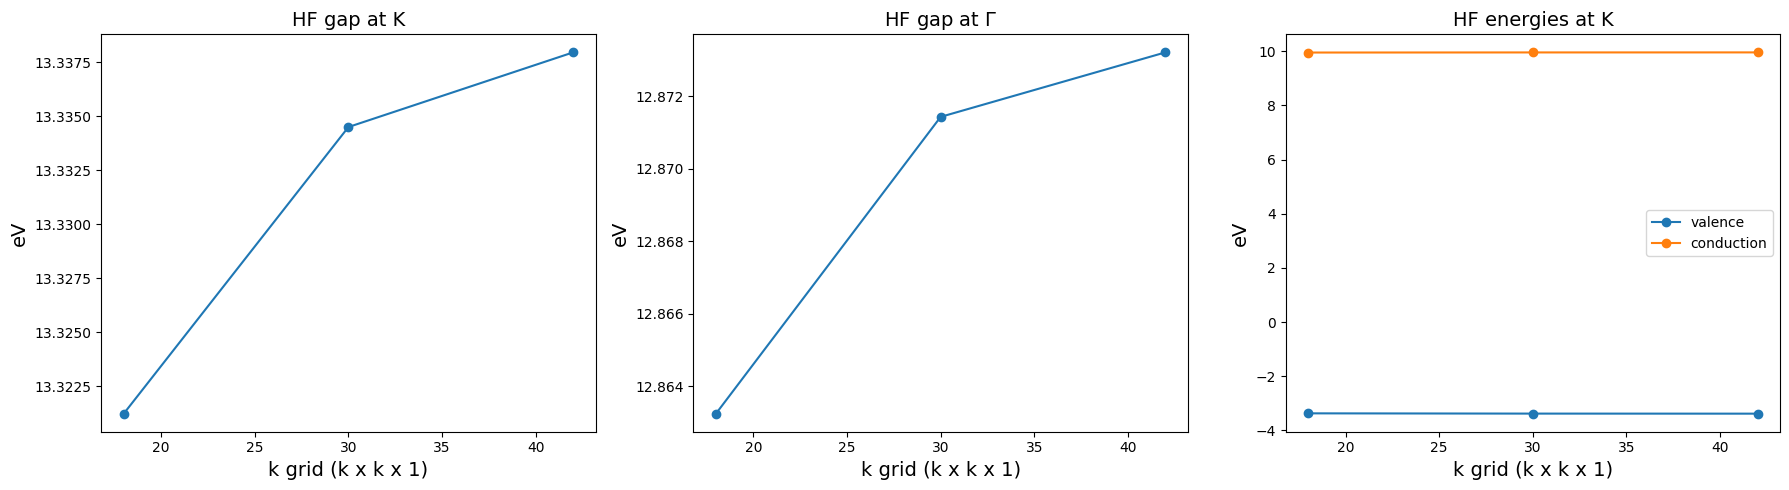

In [13]:
gap_K, gap_G, ev_K, ec_K = [], [], [], []
for k in kpoints_hf:
    folder, iK = hf_kgrid[k]['folder'], hf_kgrid[k]['K_index']
    d = np.loadtxt(os.path.join(folder, 'hf-exx_full-vxc_full', 'o-hf-exx_full-vxc_full.hf'), comments='#')
    E = {(int(r[0]), int(r[1])): r[3] for r in d}           # Ehf (eV)
    gap_K.append(E[(iK, stop_band)] - E[(iK, start_band)]); gap_G.append(E[(1, stop_band)] - E[(1, start_band)])
    ev_K.append(E[(iK, start_band)]); ec_K.append(E[(iK, stop_band)])
    print('k = %2d (K index %3d): HF gap at K = %.4f eV | at Gamma = %.4f eV | Ehf(K): v = %.4f, c = %.4f eV'
          % (k, iK, gap_K[-1], gap_G[-1], ev_K[-1], ec_K[-1]))

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))
ax[0].plot(kpoints_hf, gap_K, 'o-'); ax[0].set_title('HF gap at K', size=14)
ax[1].plot(kpoints_hf, gap_G, 'o-'); ax[1].set_title(r'HF gap at $\Gamma$', size=14)
ax[2].plot(kpoints_hf, ev_K, 'o-', label='valence'); ax[2].plot(kpoints_hf, ec_K, 'o-', label='conduction')
ax[2].set_title('HF energies at K', size=14); ax[2].legend()
for a in ax: a.set_xlabel('k grid (k x k x 1)', size=14); a.set_ylabel('eV', size=14)
fig.tight_layout()

Result: HF gaps (eV) of the monolayer vs k grid

| k grid | gap at K | gap at $\Gamma$ |
|---|---|---|
| 18x18x1 | 13.321 | 12.863 |
| 30x30x1 | 13.335 | 12.871 |
| 42x42x1 | 13.338 | 12.873 |

The HF gaps converge quickly with the slab cutoff and the RIM: 13 meV (K) and 8 meV ($\Gamma$) from 18 to 30, 3.5 and
2 meV from 30 to 42. The single HF states at K move by less than 12 meV overall. Costs: RIM 1-3 min, HF 17 s - 5 min
(18 -> 42). The k convergence of the GW corrections will be dominated by the screening (to be tested with RIM_W).

## GW (PPA) on the monolayer: size of the response matrix NGsBlkXp
`ML_bot`, k = 18x18x1. G0W0 with the Godby-Needs plasmon pole (`PPAPntXp` = 27.2 eV, default), Newton solver.
Coulomb interaction as in HF (slab z, RIM 5e6/100 from `ndb_rim_cutoff`) plus RIM_W with RandGvecW = 10 RL;
`LongDrXp = [1,1,0]` (in-plane field for the q -> 0 limit of a 2D system); EXXRLvcs = VXCRLvcs = all the G vectors
(default, HF choice above). QP corrections of bands 4, 5 at all the 37 k points of the IBZ (control quantities: gaps
at K and at $\Gamma$).

Scan: NGsBlkXp = 2, 4, 6, 8 Ha with BndsRnXp = GbndRnge = 250 (all the bands of the nscf). Each run computes
its own screening (PPA: `ndb.pp` + fragments), HF and RIM_W databases and reads only `ndb_rim_cutoff`, so the runs
are independent. After each run the screening and the RIM_W database built from it are moved to
`ndb_pp-ngsblkxp_<x>-bndsrnxp_250` (shared-database rule), to be read by the later GbndRnge scan.

Input: the RIM_W runlevel must be in the yambo command (`yambo -r -rw ...`): with `inp.activate_RIM_W()` only, the
reformat of the input (`yambo ... -F`) drops RIM_W and RandGvecW. RandGvec and RandGvecW are rounded by yambo to the
closed shells, 101 and 11 RL. Parallel structure (32 MPI): `X_and_IO_CPU = 1.1.4.8.1` (q.g.k.c.v),
`DIP_CPU = 4.8.1` (k.c.v), `SE_CPU = 2.2.8` (q.qp.b).

In [14]:
gw_cmd = '%s -r -rw -k hartee -dyson n -gw0 p -V all' % yambo_cmd
RandGvecW = 10                          # RL
LongDrXp = [1., 1., 0.]

def build_ppa_input(ngsblkxp, bndsrnxp, gbndrnge, folder=run_dir, kRange=(1, 37), terminator=False, kpoints=None):
    # kpoints: list of IBZ indices -> one QPkrange row per k point (convergence runs: only the checked points)
    inp = I.YamboInput(args=gw_cmd, folder=folder)
    inp.set_extendOut()
    inp.set_scalar_variables(CUTGeo='slab z')
    inp.set_array_variables(RandQpts=RandQpts)
    inp.set_array_variables(units='RL', RandGvec=RandGvec, RandGvecW=RandGvecW)
    inp.set_array_variables(units='Ha', NGsBlkXp=ngsblkxp)
    inp.set_array_variables(BndsRnXp=[1, bndsrnxp], GbndRnge=[1, gbndrnge], LongDrXp=LongDrXp)
    if terminator: inp.set_scalar_variables(GTermKind='BG')
    inp.set_kRange(*kRange)
    inp.set_bandRange(start_band, stop_band)
    if kpoints is not None:
        inp['variables']['QPkrange'] = [[[k, k, start_band, stop_band] for k in kpoints], '']
    inp.set_scalar_variables(X_and_IO_ROLEs='q.g.k.c.v', X_and_IO_CPU='1.1.4.8.1',
                             DIP_ROLEs='k.c.v', DIP_CPU='4.8.1', SE_ROLEs='q.qp.b', SE_CPU='2.2.8')
    return inp

def ppa_name(ngsblkxp, bndsrnxp, gbndrnge, terminator=False):
    return 'pp-ngsblkxp_%s-bndsrnxp_%s-gbndrnge_%s%s' % (ngsblkxp, bndsrnxp, gbndrnge, '-bg' if terminator else '')

def pp_name(ngsblkxp, bndsrnxp):
    return 'ndb_pp-ngsblkxp_%s-bndsrnxp_%s' % (ngsblkxp, bndsrnxp)

def share_pp(run_name, shared_name, folder=run_dir):
    # move the PPA screening (ndb.pp + fragments) and the RIM_W database built from it, of a completed run,
    # to the shared folder (skipped if already there)
    import glob, shutil
    src, dst = os.path.join(folder, run_name), os.path.join(folder, shared_name)
    files = glob.glob(os.path.join(src, 'ndb.pp*')) + glob.glob(os.path.join(src, 'ndb.RIM_W'))
    if os.path.isdir(dst) or not files: return
    os.makedirs(dst)
    for f in files: shutil.move(f, dst)
    print('moved %d files: %s -> %s' % (len(files), src, dst))

In [15]:
NGsBlkXp = [2., 4., 6., 8.]     # Ha (10 Ha run cancelled, choice 6 Ha: see below)
bnds_max = 250

code = yambo_code()
study_ngs = D.Dataset(run_dir=run_dir, num_tasks=2)
study_ngs.set_postprocessing_function(PP.yambo_parse_data)
for ngs in NGsBlkXp:
    name = ppa_name(ngs, bnds_max, bnds_max)
    study_ngs.append_run(id={'ngsblkxp': ngs}, input=build_ppa_input(ngs, bnds_max, bnds_max), runner=code,
                         run_dir=run_dir, name=name, jobname=[name, 'ndb_rim_cutoff'], skip=True)
results_ngs = study_ngs.run()
for ngs in NGsBlkXp:
    share_pp(ppa_name(ngs, bnds_max, bnds_max), pp_name(ngs, bnds_max))

Initialize a Yambo calculator with scheduler slurm
Initialize a Dataset with 2 parallel tasks


Run the selection [0, 1, 2, 3] with the parallel task_groups [[0, 1], [2, 3]] 

Run the task [0, 1] 


Skip the run of

pp-ngsblkxp_2.0-bndsrnxp_250-gbndrnge_250

Skip the run of

pp-ngsblkxp_4.0-bndsrnxp_250-gbndrnge_250

... (3 outputs left out)

Skip the run of

pp-ngsblkxp_8.0-bndsrnxp_250-gbndrnge_250

Task [2, 3] ended 
 
moved 39 files: MB_analysis/kpoints_18-nbnds_250-ML_bot/pp-ngsblkxp_2.0-bndsrnxp_250-gbndrnge_250 -> MB_analysis/kpoints_18-nbnds_250-ML_bot/ndb_pp-ngsblkxp_2.0-bndsrnxp_250


moved 39 files: MB_analysis/kpoints_18-nbnds_250-ML_bot/pp-ngsblkxp_4.0-bndsrnxp_250-gbndrnge_250 -> MB_analysis/kpoints_18-nbnds_250-ML_bot/ndb_pp-ngsblkxp_4.0-bndsrnxp_250
moved 39 files: MB_analysis/kpoints_18-nbnds_250-ML_bot/pp-ngsblkxp_6.0-bndsrnxp_250-gbndrnge_250 -> MB_analysis/kpoints_18-nbnds_250-ML_bot/ndb_pp-ngsblkxp_6.0-bndsrnxp_250
moved 39 files: MB_analysis/kpoints_18-nbnds_250-ML_bot/pp-ngsblkxp_8.0-bndsrnxp_250-gbndrnge_250 -> MB_analysis/kpoints_18-nbnds_250-ML_bot/ndb_pp-ngsblkxp_8.0-bndsrnxp_250


NGsBlkXp =  2.0 Ha | GW gap at K = 7.2284 eV | at Gamma = 7.7945 eV | E_qp(K): v = -1.0124, c = 6.2160 eV
NGsBlkXp =  4.0 Ha | GW gap at K = 7.2206 eV | at Gamma = 8.0103 eV | E_qp(K): v = -1.1265, c = 6.0941 eV
NGsBlkXp =  6.0 Ha | GW gap at K = 7.2630 eV | at Gamma = 8.1605 eV | E_qp(K): v = -1.1830, c = 6.0800 eV
NGsBlkXp =  8.0 Ha | GW gap at K = 7.2650 eV | at Gamma = 8.1819 eV | E_qp(K): v = -1.1861, c = 6.0789 eV


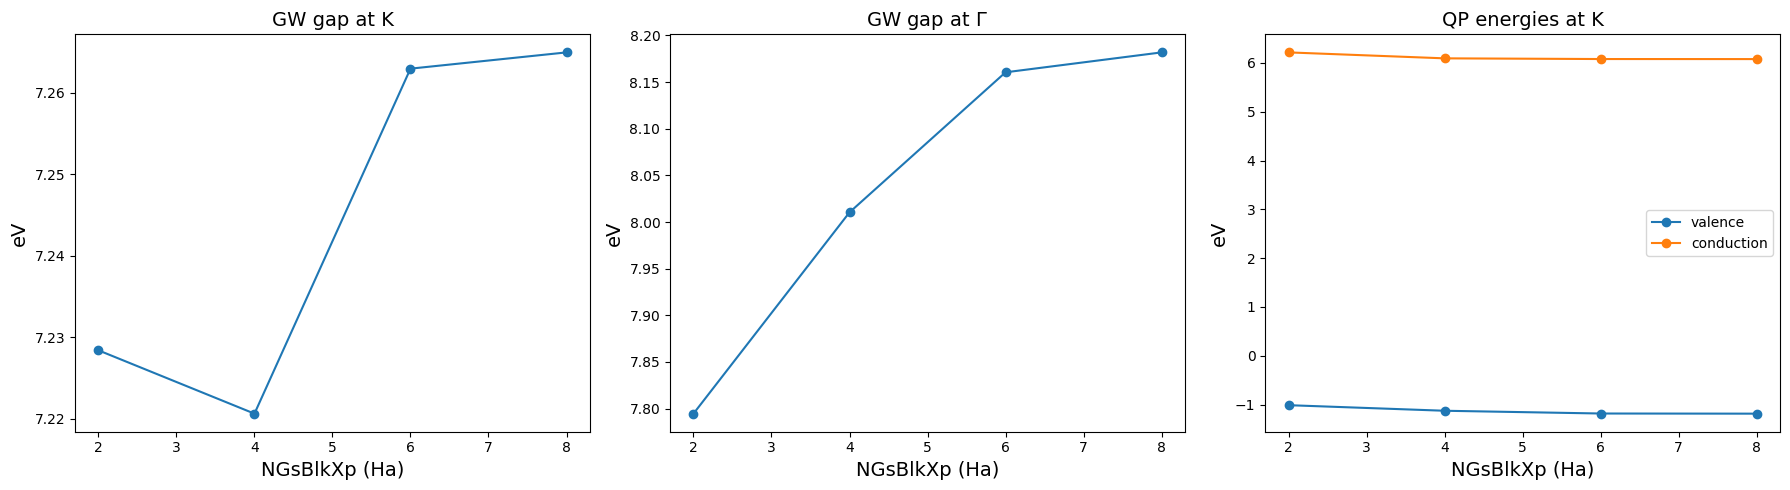

In [16]:
data = [study_ngs.fetch_results(id={'ngsblkxp': ngs})[0].data for ngs in NGsBlkXp]
gap_K = [d.get_gap(k_full=K_index, band_full=start_band) for d in data]
gap_G = [d.get_gap(k_full=Gamma_index, band_full=start_band) for d in data]
v_K = [d.get_energy(K_index, start_band) for d in data]
c_K = [d.get_energy(K_index, stop_band) for d in data]
for ngs, gk, gg, v, c in zip(NGsBlkXp, gap_K, gap_G, v_K, c_K):
    print('NGsBlkXp = %4.1f Ha | GW gap at K = %.4f eV | at Gamma = %.4f eV | E_qp(K): v = %.4f, c = %.4f eV'
          % (ngs, gk, gg, v, c))

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))
ax[0].plot(NGsBlkXp, gap_K, 'o-'); ax[0].set_title('GW gap at K', size=14)
ax[1].plot(NGsBlkXp, gap_G, 'o-'); ax[1].set_title(r'GW gap at $\Gamma$', size=14)
ax[2].plot(NGsBlkXp, v_K, 'o-', label='valence'); ax[2].plot(NGsBlkXp, c_K, 'o-', label='conduction')
ax[2].set_title('QP energies at K', size=14); ax[2].legend()
for a in ax: a.set_xlabel('NGsBlkXp (Ha)', size=14); a.set_ylabel('eV', size=14)
fig.tight_layout()

Result of the scan (k = 18, BndsRnXp = GbndRnge = 250), QP energies in eV (zero = KS valence top at K):

| NGsBlkXp (Ha) | gap at K | gap at $\Gamma$ | $E_v(K)$ | $E_c(K)$ | $E_c(\Gamma)$ |
|---|---|---|---|---|---|
| 2 | 7.228 | 7.795 | -1.012 | 6.216 | 5.302 |
| 4 | 7.221 | 8.010 | -1.127 | 6.094 | 5.353 |
| 6 | 7.263 | 8.161 | -1.183 | 6.080 | 5.361 |
| 8 | 7.265 | 8.182 | -1.186 | 6.079 | 5.361 |

The gap at K is converged from 6 Ha (+2 meV from 6 to 8 Ha); the conduction state at $\Gamma$ (NFE) is converged within
1 meV, so the minimum (indirect K -> $\Gamma$) gap, about 6.54 eV, is stable from 6 Ha too. The gap at $\Gamma$ still moves
by 21 meV from 6 to 8 Ha because of the valence state at $\Gamma$ (deep, not relevant for the benchmark at K).
Costs (1 node): 12 min (2 Ha), 27 min (4 Ha), 1 h 33 min (6 Ha), 2 h 40 min (8 Ha).

**Choice (user, 2026-11-12): NGsBlkXp = 6 Ha** (the band parameters still have to be raised; a 10 Ha run was started
and cancelled, 12 Ha only if needed later). The screening (and RIM_W) databases of the scan are in
`ndb_pp-ngsblkxp_<x>-bndsrnxp_250`.

## GW (PPA) on the monolayer: bands in the response function BndsRnXp
`ML_bot`, k = 18x18x1, NGsBlkXp = 6 Ha, GbndRnge = 250 fixed; BndsRnXp = 100, 150, 200, 250 (the 250 point is the
6 Ha run of the NGsBlkXp scan). Rule (user, 2026-11-12): in the convergence runs the QP corrections are computed only
at the checked points, here $\Gamma$ and K (bands 4, 5; two `QPkrange` rows): Sigma then costs a few minutes instead
of 71 min for the 74 states of the IBZ (the QP energy of a state does not depend on the other states computed).
Each run computes its own screening (different BndsRnXp) and reads only `ndb_rim_cutoff`; afterwards `ndb.pp` and
`ndb.RIM_W` are moved to `ndb_pp-ngsblkxp_6.0-bndsrnxp_<n>`.

In [ ]:
ngs_conv = 6.                            # Ha (choice above)
BndsRnXp = [100, 150, 200]               # + 250 from the NGsBlkXp scan
qp_kpoints = [Gamma_index, K_index]

code = yambo_code()
study_bnd = D.Dataset(run_dir=run_dir, num_tasks=2)
study_bnd.set_postprocessing_function(PP.yambo_parse_data)
for nb_x in BndsRnXp:
    name = ppa_name(ngs_conv, nb_x, bnds_max)
    study_bnd.append_run(id={'bndsrnxp': nb_x}, input=build_ppa_input(ngs_conv, nb_x, bnds_max, kpoints=qp_kpoints),
                         runner=code, run_dir=run_dir, name=name, jobname=[name, 'ndb_rim_cutoff'], skip=True)
results_bnd = study_bnd.run()
for nb_x in BndsRnXp:
    share_pp(ppa_name(ngs_conv, nb_x, bnds_max), pp_name(ngs_conv, nb_x))

In [ ]:
def qp_table(name):
    # E_qp (eV) of the o-*.qp file of a run, {(k, b): E}
    d = np.loadtxt(os.path.join(run_dir, name, 'o-%s.qp' % name), comments='#')
    return {(int(r[0]), int(r[1])): r[3] for r in d}

bnd_all = BndsRnXp + [bnds_max]
E = [qp_table(ppa_name(ngs_conv, nb_x, bnds_max)) for nb_x in bnd_all]
gap_K = [e[(K_index, stop_band)] - e[(K_index, start_band)] for e in E]
gap_G = [e[(Gamma_index, stop_band)] - e[(Gamma_index, start_band)] for e in E]
gap_KG = [e[(Gamma_index, stop_band)] - e[(K_index, start_band)] for e in E]
for nb_x, gk, gg, gi, e in zip(bnd_all, gap_K, gap_G, gap_KG, E):
    print('BndsRnXp = %3d | GW gap at K = %.4f | at Gamma = %.4f | K->Gamma = %.4f | Ev(K) = %.4f Ec(K) = %.4f Ec(G) = %.4f eV'
          % (nb_x, gk, gg, gi, e[(K_index, start_band)], e[(K_index, stop_band)], e[(Gamma_index, stop_band)]))

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))
ax[0].plot(bnd_all, gap_K, 'o-'); ax[0].set_title('GW gap at K', size=14)
ax[1].plot(bnd_all, gap_G, 'o-'); ax[1].set_title(r'GW gap at $\Gamma$', size=14)
ax[2].plot(bnd_all, gap_KG, 'o-'); ax[2].set_title(r'GW gap K $\to\Gamma$', size=14)
for a in ax: a.set_xlabel('BndsRnXp', size=14); a.set_ylabel('eV', size=14)
fig.tight_layout()